In [1]:
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
data = fetch_ucirepo(id=292)
X = data.data.features[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]]

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [4]:
model = KMeans(n_clusters=3, random_state=42, n_init=10)

In [5]:
clusters = model.fit_predict(X_scaled)
X_result = X.copy()
X_result["Cluster"] = clusters
print("\nCluster Assignments:")
print(X_result.head(10))
print("\nInertia:", model.inertia_)
print("Silhouette Score:",silhouette_score(X_scaled, clusters))


Cluster Assignments:
   Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicassen  Cluster
0  12669   9656     7561     214              2674        1338        1
1   7057   9810     9568    1762              3293        1776        1
2   6353   8808     7684    2405              3516        7844        1
3  13265   1196     4221    6404               507        1788        1
4  22615   5410     7198    3915              1777        5185        1
5   9413   8259     5126     666              1795        1451        1
6  12126   3199     6975     480              3140         545        1
7   7579   4956     9426    1669              3321        2566        1
8   5963   3648     6192     425              1716         750        1
9   6006  11093    18881    1159              7425        2098        0

Inertia: 1608.4311488289443
Silhouette Score: 0.5482872649700601


In [6]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

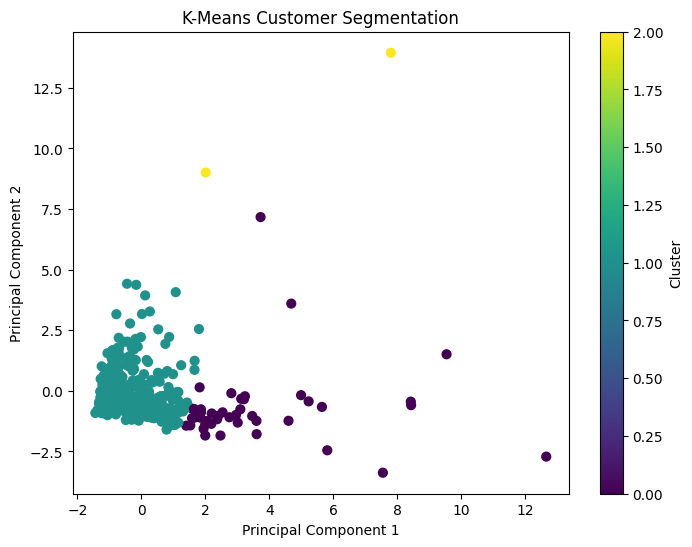

In [7]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="viridis", s=40)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Customer Segmentation")
plt.colorbar(scatter, label="Cluster")
plt.show()

In [8]:
print("\nCustomers in Each Cluster:")
print(X_result["Cluster"].value_counts().sort_index())


Customers in Each Cluster:
Cluster
0     45
1    393
2      2
Name: count, dtype: int64
